# Chương 2: Thực Nghiệm & Đánh Giá Thuật Toán `negFIN` (Local — Pure Julia)

Phiên bản dành riêng để chạy **local**  chạy trực tiếp trên mã nguồn và bộ dữ liệu sẵn có trong repository.

### Hướng dẫn chạy trên máy Local
1. Đảm bảo đang mở thư mục dự án `Frequent_Itemset_Mining` (đã có `data/benchmark/*.txt` và gói Julia trong môi trường).
2. Chọn **Kernel: Julia** trong VS Code hoặc Jupyter.
3. Bấm **Run All** để thực thi trực tiếp (mặc định đọc CSV có sẵn để vẽ nhanh; đổi `FORCE_RERUN = true` ở Phần 2 nếu muốn chạy lại benchmark).

### Mục lục các phần trong Notebook
- **Phần 1:** Nạp đường dẫn dự án & môi trường Julia local.
- **Phần 2:** Chạy bộ thực nghiệm tự động (`scripts/run_benchmarks.jl`) và nạp cấu hình biểu đồ.
- **Phần 3 — Thực nghiệm 1:** Kiểm tra tính đúng đắn (**Correctness**).
- **Phần 4 — Thực nghiệm 2:** Thời gian chạy theo ngưỡng hỗ trợ (**Runtime vs. `minsup`**).
- **Phần 5 — Thực nghiệm 3:** Số lượng tập phổ biến (**Output Size** — Dense vs. Sparse).
- **Phần 6 — Thực nghiệm 4:** Mức sử dụng bộ nhớ (**Heap Allocated & Peak RSS**).
- **Phần 7 — Thực nghiệm 5:** Khả năng mở rộng (**Scalability** 10% $\rightarrow$ 100%).
- **Phần 8 — Thực nghiệm 6:** Ảnh hưởng của **độ dài giao dịch trung bình** (Synthetic).
- **Phần 9:** Phân tích chuyên sâu theo lý thuyết bài báo & Đề xuất hướng tối ưu tiếp theo.

---
## Phần 1: Nạp Đường Dẫn Dự Án Local

Tự động xác định thư mục gốc chứa `Project.toml` và kích hoạt môi trường Julia sẵn có (không tải dữ liệu, không cài thêm gói).

In [9]:
using Pkg: Pkg

function find_project_root()::String
    dir = pwd()
    for _ in 1:4
        if isfile(joinpath(dir, "Project.toml")) &&
           isfile(joinpath(dir, "scripts", "run_benchmarks.jl"))
            return dir
        end
        parent = dirname(dir)
        parent == dir && break
        dir = parent
    end
    error("Không tìm thấy thư mục gốc chứa Project.toml")
end

const ROOT_DIR = find_project_root()
const LOGS_DIR = joinpath(ROOT_DIR, "results", "logs")
const FIG_DIR = joinpath(ROOT_DIR, "results", "figures")
mkpath(LOGS_DIR)
mkpath(FIG_DIR)
Pkg.activate(ROOT_DIR)
println("Julia version: ", VERSION)
println("Project root:  ", ROOT_DIR)

  Activating 

Julia version: 1.11.9
Project root:  /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining


project at `~/Documents/Material/AI/DataMining/Frequent_Itemset_Mining`


---
## Phần 2: Thực Thi Bộ Benchmark Tự Động & Khởi Tạo Cấu Hình Biểu Đồ

Toàn bộ 6 thực nghiệm được đóng gói trong `scripts/run_benchmarks.jl` với quy chuẩn đo đạc chặt chẽ:
- **Warm-up JIT:** Chạy nháp 1 lần trước khi bấm giờ để loại trừ thời gian biên dịch JIT của Julia.
- **Độ ổn định thời gian:** Lặp lại 3 lần (`repeats = 3`), lấy **trung vị (median)** thời gian chạy.
- **Đo bộ nhớ 2 lớp:** Kết hợp `@allocated` (tổng Heap cấp phát) và **Peak RSS** tiến trình con qua `/usr/bin/time`.
- **Tính tái lập (Reproducibility):** Cố định `MersenneTwister(42 + i)` cho toàn bộ dữ liệu tổng hợp.

> *Mẹo:* Nếu các file CSV trong `results/logs/` đã tồn tại và bạn chỉ muốn vẽ lại biểu đồ, hãy đặt `FORCE_RERUN = false`.

In [10]:
const FORCE_RERUN = false  # Đặt true để chạy lại toàn bộ 6 thực nghiệm từ đầu

if FORCE_RERUN || !isfile(joinpath(LOGS_DIR, "exp6_tx_length.csv"))
    include(joinpath(ROOT_DIR, "scripts", "run_benchmarks.jl"))
    run_all_experiments()
else
    println("[OK] Đã có sẵn các file CSV kết quả trong: ", LOGS_DIR)
end

# Nạp thư viện đọc dữ liệu và cấu hình Plots.jl chuẩn xuất bản (300 DPI)
using CSV: CSV
using DataFrames: DataFrame, combine, groupby, nrow
using Plots: Plots, RGB, bar, bar!, default, gr, plot, plot!, savefig, twinx

gr()
default(
    dpi=300,
    titlefontsize=11,
    guidefontsize=9,
    tickfontsize=8,
    legendfontsize=8,
    grid=true,
    gridalpha=0.3,
    framestyle=:box,
)

[OK] Đã có sẵn các file CSV kết quả trong: /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/results/logs


---
## Phần 3 — Thực Nghiệm 1: Kiểm Tra Tính Đúng Đắn (Correctness)

### Mục tiêu & Thiết lập
- Chạy song song `negfin_baseline` và `negfin_optimized` trên cả **5/5 bộ dữ liệu benchmark** tại các ngưỡng `minsup` đại diện (`chess=0.80`, `mushroom=0.30`, `accidents=0.70`, `retail=0.02`, `T10I4D100K=0.02`).
- Đối chiếu tự động từng tập phổ biến và giá trị `support` tương ứng bằng `compare_results` (kiểm tra cả trùng lặp, thiếu/thừa tập và sai lệch support). Nếu môi trường có JVM tương thích `spmf.jar`, hệ thống cũng đối chiếu trực tiếp với `SPMF negFIN`.

In [11]:
df_corr = CSV.read(joinpath(LOGS_DIR, "exp1_correctness.csv"), DataFrame)
println("=== BẢNG KẾT QUẢ THỰC NGHIỆM 1: CORRECTNESS ===")
display(df_corr)

all_match = all(df_corr.base_vs_opt_match .== "MATCH_100%")
println("\nKết luận đối chiếu Baseline vs. Optimized: ", all_match ? "KHỚP 100%" : "LỆCH")

Row,dataset,minsup,n_tx,itemsets_base,itemsets_opt,base_vs_opt_match,spmf_match
,DataStri…,Float64,Int64,Int64,Int64,DataStri…,DataStri…
1,chess,0.8,3196,8227,8227,MATCH_100%,SKIPPED_JVM
2,mushroom,0.3,8416,2587,2587,MATCH_100%,SKIPPED_JVM
3,accidents,0.7,340183,529,529,MATCH_100%,SKIPPED_JVM
4,retail,0.02,88162,55,55,MATCH_100%,SKIPPED_JVM
5,T10I4D100K,0.02,100000,155,155,MATCH_100%,SKIPPED_JVM


=== BẢNG KẾT QUẢ THỰC NGHIỆM 1: CORRECTNESS ===

Kết luận đối chiếu Baseline vs. Optimized: KHỚP 100%


### Nhận xét Thực nghiệm 1
- Cả hai phiên bản **Baseline** (`BitVector`) và **Optimized** (bit-packing đa chiều + LCRS BMC-tree + Early-Abort + zero-alloc Promotion) đều cho kết quả **khớp tuyệt đối 100%** trên cả 5 bộ benchmark (tổng số itemsets và `support` của từng itemset giống hệt nhau).
- Điều này chứng minh các kỹ thuật tối ưu hóa ở bản `negfin_optimized.jl` bảo toàn nguyên vẹn tính đúng đắn toán học của thuật toán gốc.

---
## Phần 4 — Thực Nghiệm 2: Thời Gian Chạy Theo `minsup` (Runtime Comparison)

### Mục tiêu & Thiết lập
- Đánh giá tốc độ khai thác trên **6 mốc `minsup`** giảm dần cho mỗi bộ dữ liệu:
  - `Chess`: 90% $\rightarrow$ 65% | `Mushroom`: 40% $\rightarrow$ 15% | `Accidents`: 75% $\rightarrow$ 50%
  - `Retail`: 5.0% $\rightarrow$ 0.3% | `T10I4D100K`: 4.0% $\rightarrow$ 0.7%
- Vẽ chung đường cong **Baseline (Julia)**, **Optimized (Julia)** (và **SPMF (Java)** nếu có) trên cùng hệ trục với trục hoành đảo ngược (`minsup` giảm từ trái sang phải).

Row,dataset,kind,min_speedup,max_speedup,max_opt_time_s
,DataStri…,DataStri…,Float64,Float64,Float64
1,chess,dense,1.097,1.723,0.009835
2,mushroom,dense,1.238,1.564,0.008306
3,accidents,dense,1.079,1.177,0.413466
4,retail,sparse,1.112,1.411,0.40331
5,T10I4D100K,sparse,1.116,3.262,0.837988


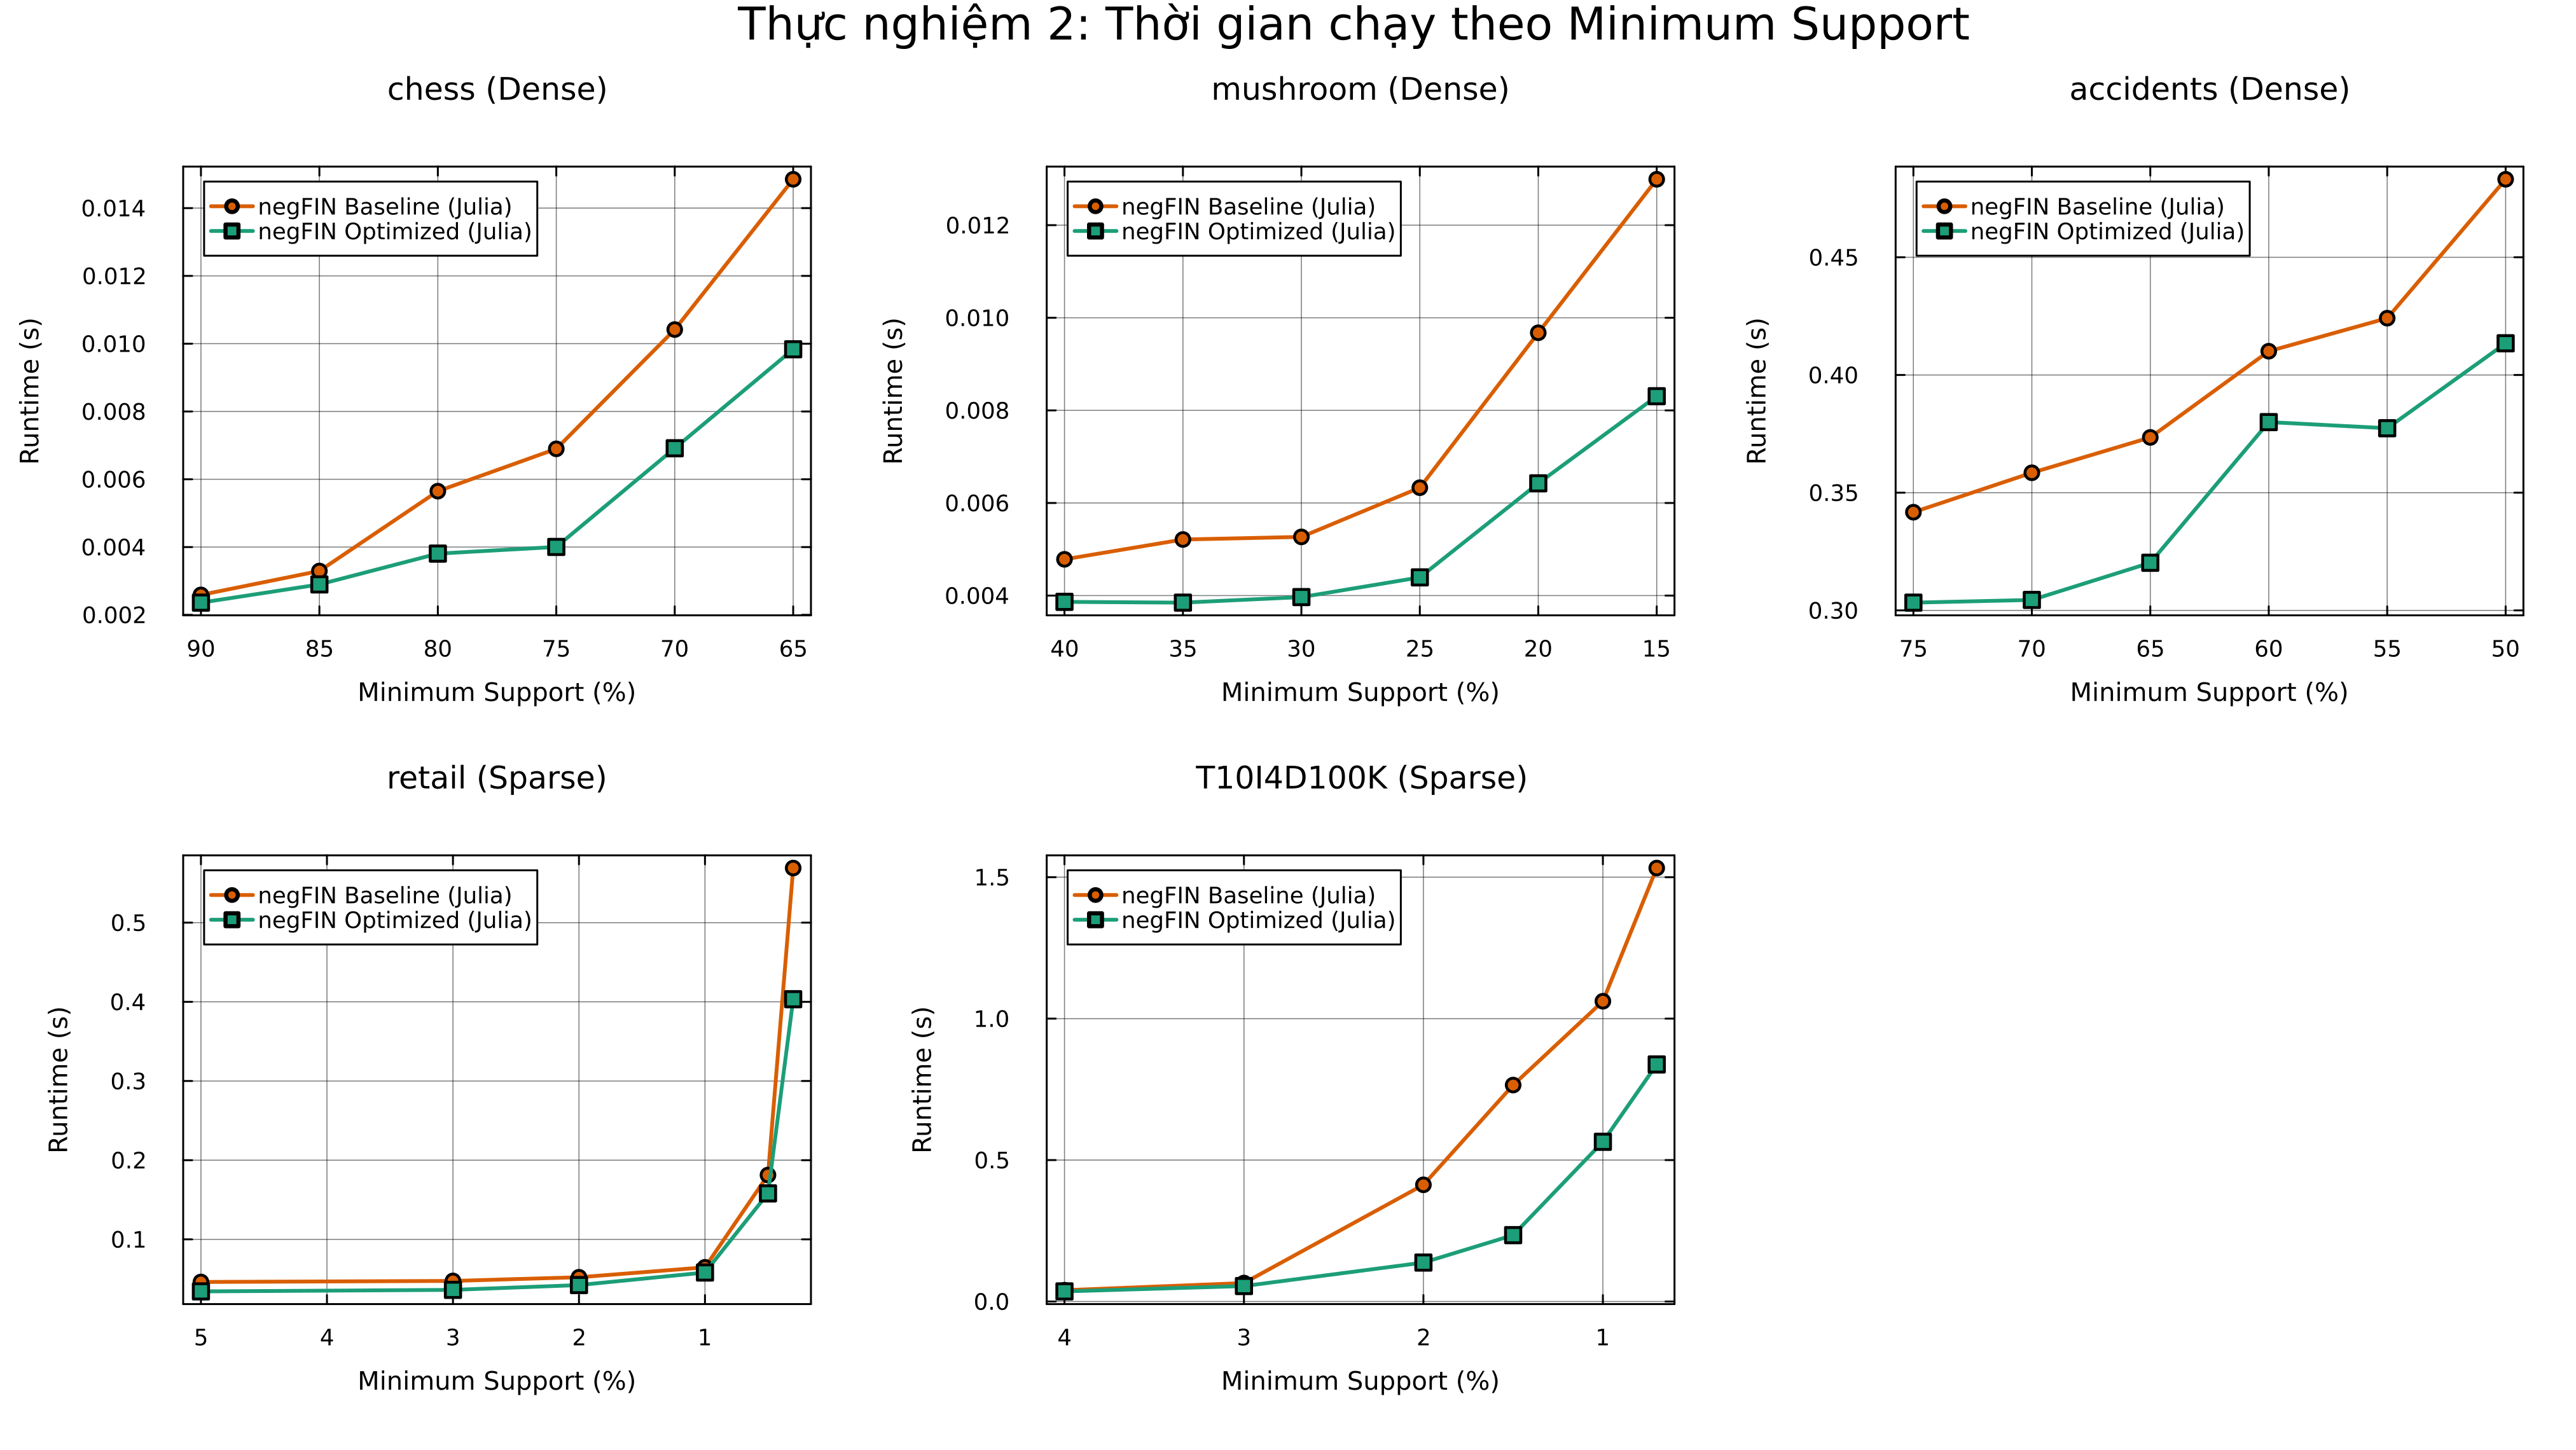

=== TÓM TẮT TỐC ĐỘ (BASELINE vs. OPTIMIZED) ===


In [12]:
df_rt = CSV.read(joinpath(LOGS_DIR, "exp2_3_runtime_output.csv"), DataFrame)

# Bảng tóm tắt hệ số tăng tốc (Speedup) theo từng CSDL
df_speedup = combine(
    groupby(df_rt, [:dataset, :kind]),
    :speedup => minimum => :min_speedup,
    :speedup => maximum => :max_speedup,
    :time_opt_s => maximum => :max_opt_time_s,
)
println("=== TÓM TẮT TỐC ĐỘ (BASELINE vs. OPTIMIZED) ===")
display(df_speedup)

dataset_names = unique(df_rt.dataset)
subplots = Plots.Plot[]
for ds in dataset_names
    sub = sort(filter(row -> row.dataset == ds, df_rt), :minsup; rev=true)
    x_pct = sub.minsup .* 100.0
    kind_label = uppercasefirst(String(sub.kind[1]))

    p = plot(
        x_pct,
        sub.time_base_s;
        label="negFIN Baseline (Julia)",
        marker=:circle,
        linewidth=2,
        color=RGB(0.85, 0.37, 0.01),
        xflip=true,
        xlabel="Minimum Support (%)",
        ylabel="Runtime (s)",
        title="$ds ($kind_label)",
        legend=:topleft,
    )
    plot!(
        p,
        x_pct,
        sub.time_opt_s;
        label="negFIN Optimized (Julia)",
        marker=:rect,
        linewidth=2,
        color=RGB(0.11, 0.62, 0.47),
    )
    if hasproperty(sub, :time_spmf_s) && any(!ismissing, sub.time_spmf_s)
        valid_idx = findall(!ismissing, sub.time_spmf_s)
        plot!(
            p,
            x_pct[valid_idx],
            Float64.(sub.time_spmf_s[valid_idx]);
            label="SPMF negFIN (Java)",
            marker=:utriangle,
            linestyle=:dash,
            linewidth=1.8,
            color=RGB(0.46, 0.44, 0.70),
        )
    end
    push!(subplots, p)
end
push!(subplots, plot(; framestyle=:none, grid=false, axis=false))

fig1 = plot(
    subplots...;
    layout=(2, 3),
    size=(1350, 760),
    plot_title="Thực nghiệm 2: Thời gian chạy theo Minimum Support",
    margin=5Plots.mm,
)
savefig(fig1, joinpath(FIG_DIR, "fig1_runtime_vs_minsup.png"))
display(fig1)

### Nhận xét Thực nghiệm 2
- Bản **Optimized** nhanh hơn **Baseline** ở tất cả các mốc trên cả 5 tập dữ liệu, nổi bật nhất trên `T10I4D100K` (đạt tới **3.26x** ở `minsup = 1.5%`, giảm từ `0.765s` xuống `0.235s`) và `Chess` (**1.72x** ở `minsup = 75%`).
- Trên tập cực lớn `Accidents` (340,183 giao dịch), `negfin_optimized` chỉ mất **0.30–0.41 giây**; trên `Chess` (65%, 111,239 itemsets) chỉ mất **9.8 ms**.
- **Lý giải theo lý thuyết:** `negFIN` chỉ cần duyệt 1 tập nút (`O(n)`) kèm thao tác bitwise `O(1)`. Khi kết hợp Multiple Dispatch (`UInt64`/`UInt128` không cấp phát heap) và **Early-Abort** (dừng vòng lặp ngay khi `neg_sup > parent_sup - min_sup_count`), chi phí duyệt các nhánh không phổ biến trên `T10I4D100K` giảm mạnh.

---
## Phần 5 — Thực Nghiệm 3: Số Lượng Tập Phổ Biến (Output Size — Dense vs. Sparse)

### Mục tiêu & Thiết lập
- Quan sát tốc độ tăng trưởng của số lượng tập phổ biến (`n_itemsets`) khi giảm dần `minsup` trên thang đo logarit (`yscale = :log10`), tách riêng nhóm **Dày đặc (Dense)** và nhóm **Thưa (Sparse)**.

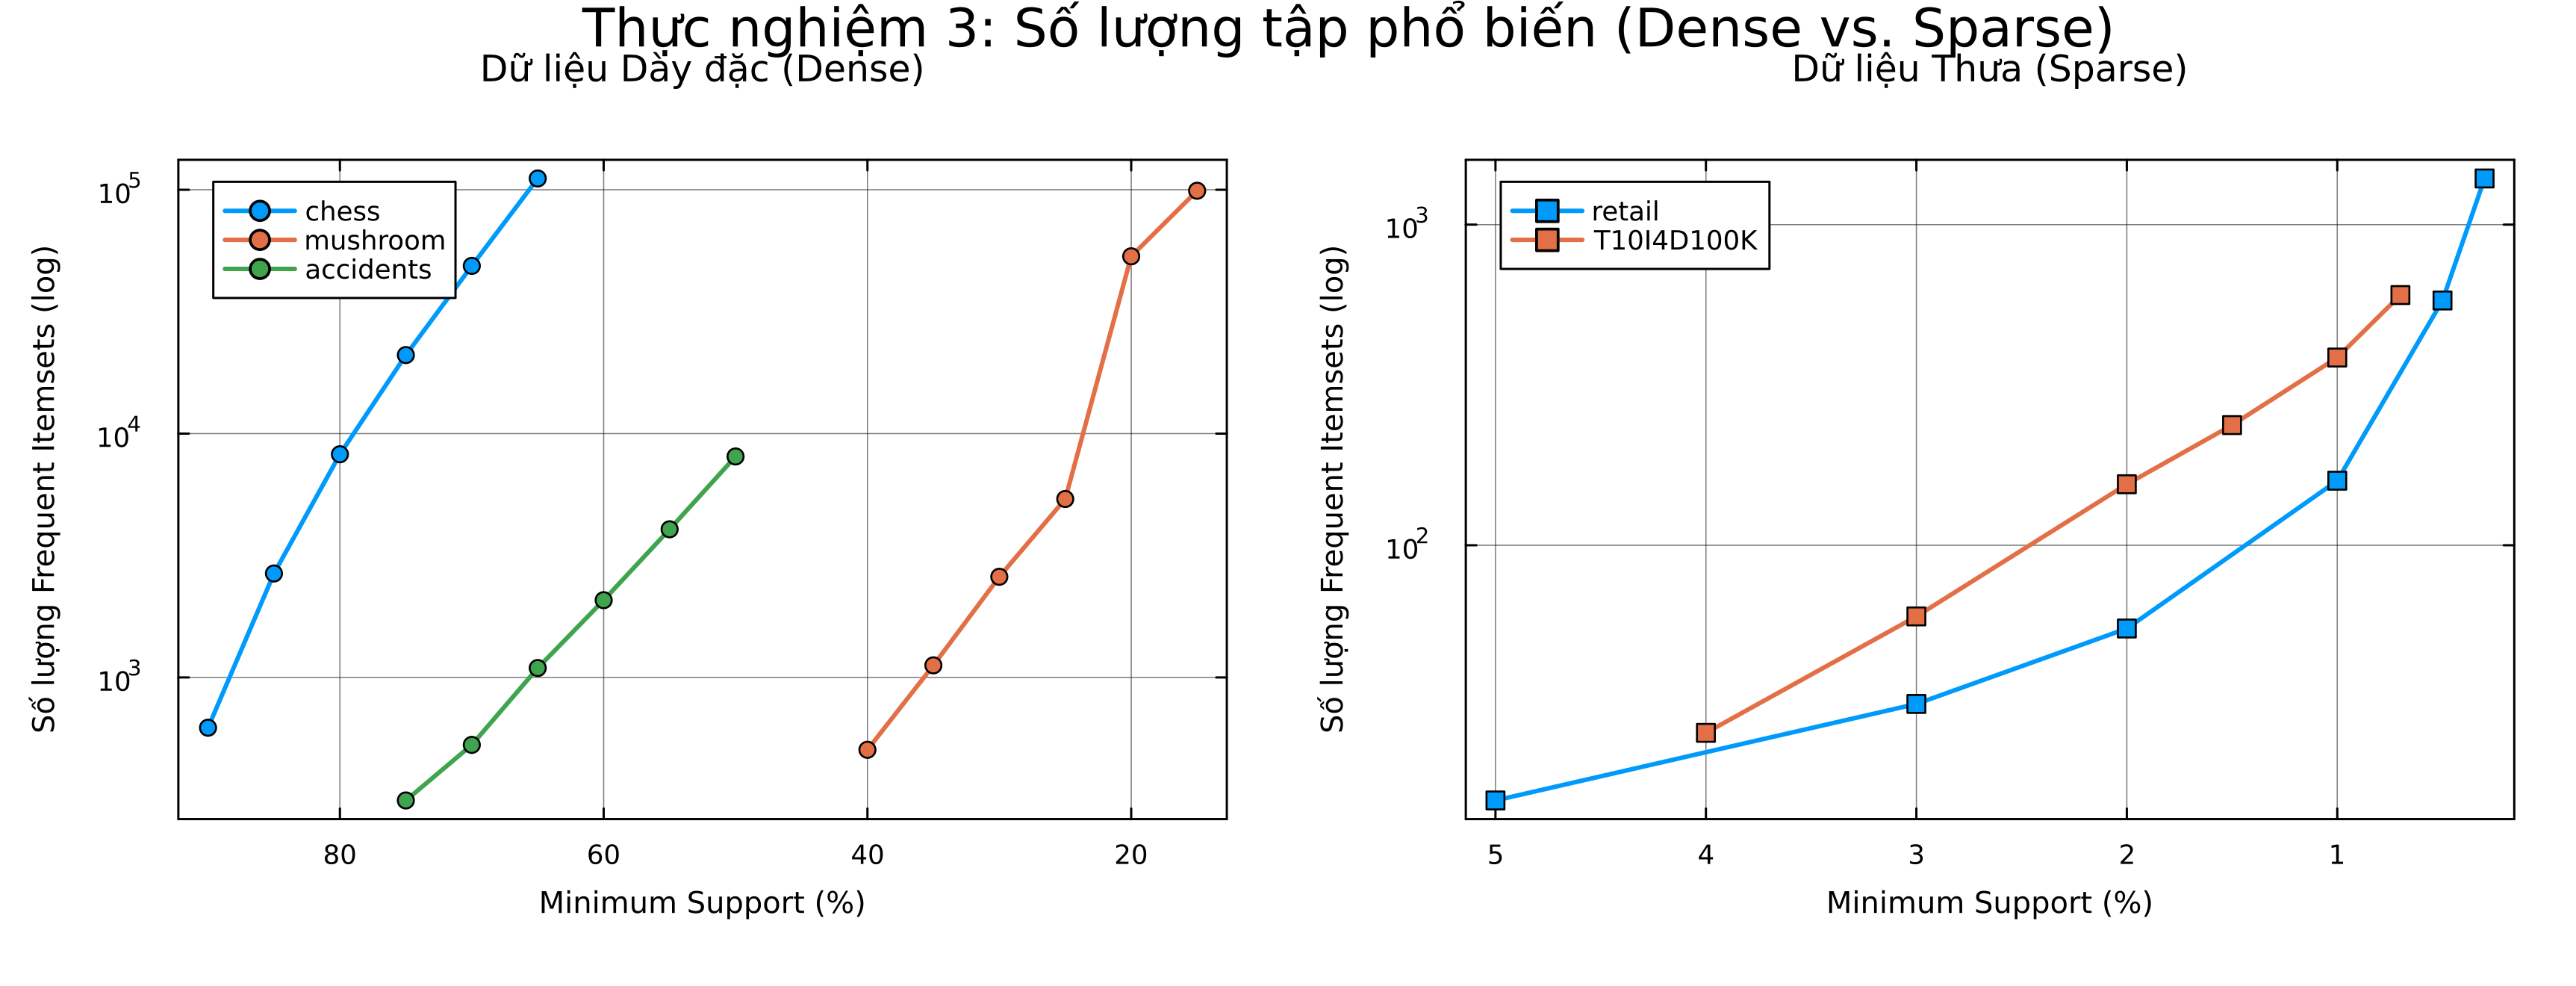

In [13]:
p_dense = plot(
    ;
    title="Dữ liệu Dày đặc (Dense)",
    xlabel="Minimum Support (%)",
    ylabel="Số lượng Frequent Itemsets (log)",
    yscale=:log10,
    xflip=true,
    legend=:topleft,
)
for ds in unique(filter(r -> r.kind == "dense", df_rt).dataset)
    sub = sort(filter(r -> r.dataset == ds, df_rt), :minsup; rev=true)
    plot!(
        p_dense, sub.minsup .* 100.0, sub.n_itemsets;
        label=ds, marker=:circle, linewidth=2,
    )
end

p_sparse = plot(
    ;
    title="Dữ liệu Thưa (Sparse)",
    xlabel="Minimum Support (%)",
    ylabel="Số lượng Frequent Itemsets (log)",
    yscale=:log10,
    xflip=true,
    legend=:topleft,
)
for ds in unique(filter(r -> r.kind == "sparse", df_rt).dataset)
    sub = sort(filter(r -> r.dataset == ds, df_rt), :minsup; rev=true)
    plot!(
        p_sparse, sub.minsup .* 100.0, sub.n_itemsets;
        label=ds, marker=:rect, linewidth=2,
    )
end

fig2 = plot(
    p_dense,
    p_sparse;
    layout=(1, 2),
    size=(1150, 440),
    plot_title="Thực nghiệm 3: Số lượng tập phổ biến (Dense vs. Sparse)",
    margin=5Plots.mm,
)
savefig(fig2, joinpath(FIG_DIR, "fig2_output_size.png"))
display(fig2)

### Nhận xét Thực nghiệm 3
- **Dữ liệu Dense (`Chess`, `Mushroom`, `Accidents`):** Các item có độ tương quan rất cao và chiều dài giao dịch lớn (23–37 items/tx), nên khi giảm `minsup`, số tập phổ biến **bùng nổ theo hàm mũ** (thể hiện qua đường gần thẳng trên trục log: `Chess` tăng từ `622` lên `111,239`, `Mushroom` tăng từ `505` lên `99,071`).
- **Dữ liệu Sparse (`Retail`, `T10I4D100K`):** Không gian item rất rộng nhưng giao dịch ngắn (~10 items/tx), do đó ngay cả ở `minsup` rất thấp (`0.3%–0.7%`), số tập phổ biến vẫn chỉ ở mức vài trăm đến hơn một nghìn.
- Trên dữ liệu Dense, kỹ thuật **Superset Equivalence / Promotion** (Property 9) của `negFIN` phát huy tối đa sức mạnh khi sinh trực tiếp hàng chục nghìn tập phổ biến đồng support mà không phải mở rộng cây tìm kiếm.

---
## Phần 6 — Thực Nghiệm 4: Mức Sử Dụng Bộ Nhớ (Heap Allocated & Peak RSS)

### Mục tiêu & Thiết lập
- So sánh trực tiếp bộ nhớ giữa **Baseline** và **Optimized** tại ngưỡng `minsup` trung bình của từng bộ dữ liệu theo hai chỉ số:
  1. **Heap Allocation (`@allocated`):** Tổng dung lượng bộ nhớ động cấp phát trong suốt quá trình khai thác (phản ánh trực tiếp áp lực lên Garbage Collector).
  2. **Peak RSS:** RAM vật lý đỉnh thực tế của tiến trình Julia con đo bằng `/usr/bin/time`.

Row,dataset,minsup,alloc_base_mb,alloc_opt_mb,alloc_reduction_pct,peak_rss_base_mb,peak_rss_opt_mb
,DataStri…,Float64,Float64,Float64,Float64,Float64,Float64
1,chess,0.75,11.747,7.416,36.87,309.45,308.23
2,mushroom,0.25,4.7,1.88,60.0,309.45,309.06
3,accidents,0.6,25.612,7.799,69.55,451.05,444.02
4,retail,0.01,45.904,22.945,50.01,347.27,337.08
5,T10I4D100K,0.015,1719.26,1246.12,27.52,449.08,372.5


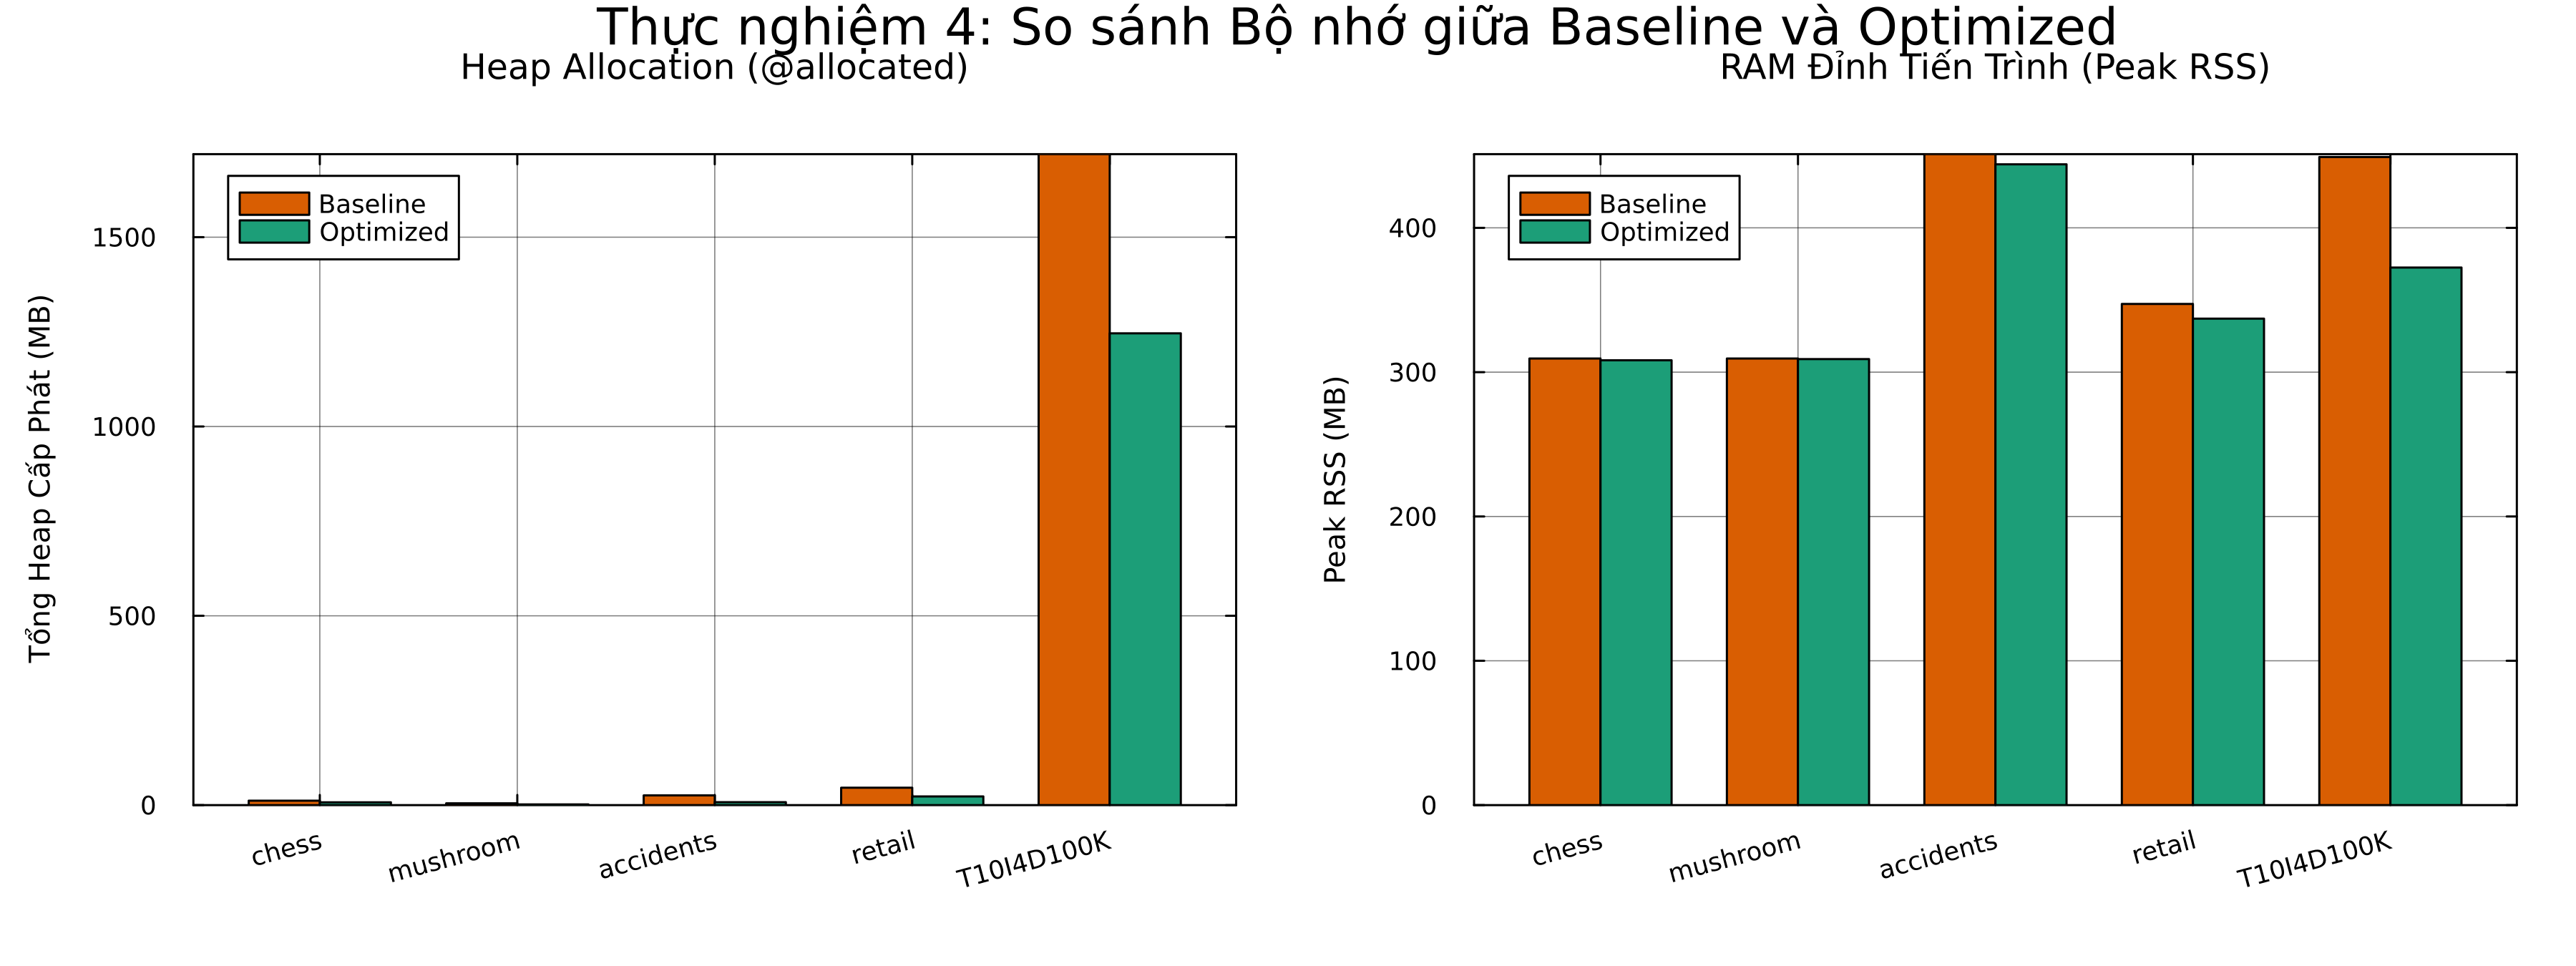

=== BẢNG KẾT QUẢ THỰC NGHIỆM 4: BỘ NHỚ ===


In [14]:
df_mem = CSV.read(joinpath(LOGS_DIR, "exp4_memory.csv"), DataFrame)
println("=== BẢNG KẾT QUẢ THỰC NGHIỆM 4: BỘ NHỚ ===")
display(df_mem)

x_idx = collect(1:nrow(df_mem))
w = 0.36

p_alloc = bar(
    x_idx .- w / 2,
    df_mem.alloc_base_mb;
    bar_width=w,
    label="Baseline",
    color=RGB(0.85, 0.37, 0.01),
    xticks=(x_idx, df_mem.dataset),
    xrotation=15,
    ylabel="Tổng Heap Cấp Phát (MB)",
    title="Heap Allocation (@allocated)",
    legend=:topleft,
)
bar!(
    p_alloc,
    x_idx .+ w / 2,
    df_mem.alloc_opt_mb;
    bar_width=w,
    label="Optimized",
    color=RGB(0.11, 0.62, 0.47),
)

p_rss = bar(
    x_idx .- w / 2,
    df_mem.peak_rss_base_mb;
    bar_width=w,
    label="Baseline",
    color=RGB(0.85, 0.37, 0.01),
    xticks=(x_idx, df_mem.dataset),
    xrotation=15,
    ylabel="Peak RSS (MB)",
    title="RAM Đỉnh Tiến Trình (Peak RSS)",
    legend=:topleft,
)
bar!(
    p_rss,
    x_idx .+ w / 2,
    df_mem.peak_rss_opt_mb;
    bar_width=w,
    label="Optimized",
    color=RGB(0.11, 0.62, 0.47),
)

fig3 = plot(
    p_alloc,
    p_rss;
    layout=(1, 2),
    size=(1200, 450),
    plot_title="Thực nghiệm 4: So sánh Bộ nhớ giữa Baseline và Optimized",
    margin=5Plots.mm,
)
savefig(fig3, joinpath(FIG_DIR, "fig3_memory_comparison.png"))
display(fig3)

### Nhận xét Thực nghiệm 4
- Bản **Optimized** giảm tổng bộ nhớ Heap cấp phát từ **27.5% đến 69.5%** trên cả 5 bộ dữ liệu (`Accidents`: -69.5%, `Mushroom`: -60.0%, `Retail`: -50.0%, `Chess`: -36.9%, `T10I4D100K`: -27.5%).
- Về **Peak RSS** thực tế, tập `T10I4D100K` (có số nút BMC-tree và kích thước `n_f` lớn) giảm rõ rệt từ **449.1 MB xuống 372.5 MB** (tiết kiệm 76.6 MB RAM vật lý).
- **Nguyên nhân:** Biểu diễn cây **LCRS (`BMCNodeOpt{B}`)** loại bỏ hàng trăm nghìn `Vector` rỗng ở nút lá, **bit-packing** bằng `UInt64`/`UInt128`/`NTuple` bỏ hoàn toàn heap wrapper của `BitVector`, kết hợp giải phóng sớm `nodesets[pos]` sau khi duyệt xong từng nhánh tầng 1.

---
## Phần 7 — Thực Nghiệm 5: Khả Năng Mở Rộng (Scalability 10% $\rightarrow$ 100%)

### Mục tiêu & Thiết lập
- Chọn 2 bộ dữ liệu kích thước lớn đại diện cho cả hai loại: **`Retail`** (Sparse, 88,162 tx, `minsup = 0.5%`) và **`Accidents`** (Dense, 340,183 tx, `minsup = 55%`).
- Cắt lát dữ liệu theo các mốc **10%, 25%, 50%, 75%, 100%** số giao dịch, giữ nguyên tỷ lệ `minsup` tương đối và đo thời gian chạy của cả hai phiên bản.

Row,dataset,minsup,fraction,n_tx,n_itemsets,time_base_s,time_opt_s,alloc_opt_mb
,DataStri…,Float64,Float64,Int64,Int64,Float64,Float64,Float64
1,retail,0.005,0.1,8816,692,0.028316,0.01455,60.821
2,retail,0.005,0.25,22040,659,0.047148,0.039156,113.238
3,retail,0.005,0.5,44081,613,0.108693,0.072558,200.474
4,retail,0.005,0.75,66122,544,0.139522,0.106894,294.985
5,retail,0.005,1.0,88162,580,0.182426,0.151131,366.776
6,accidents,0.55,0.1,34018,3628,0.047206,0.03522,7.465
7,accidents,0.55,0.25,85046,3991,0.110882,0.087991,9.473
8,accidents,0.55,0.5,170092,4160,0.221569,0.184749,13.01
9,accidents,0.55,0.75,255137,4010,0.428876,0.279695,14.541


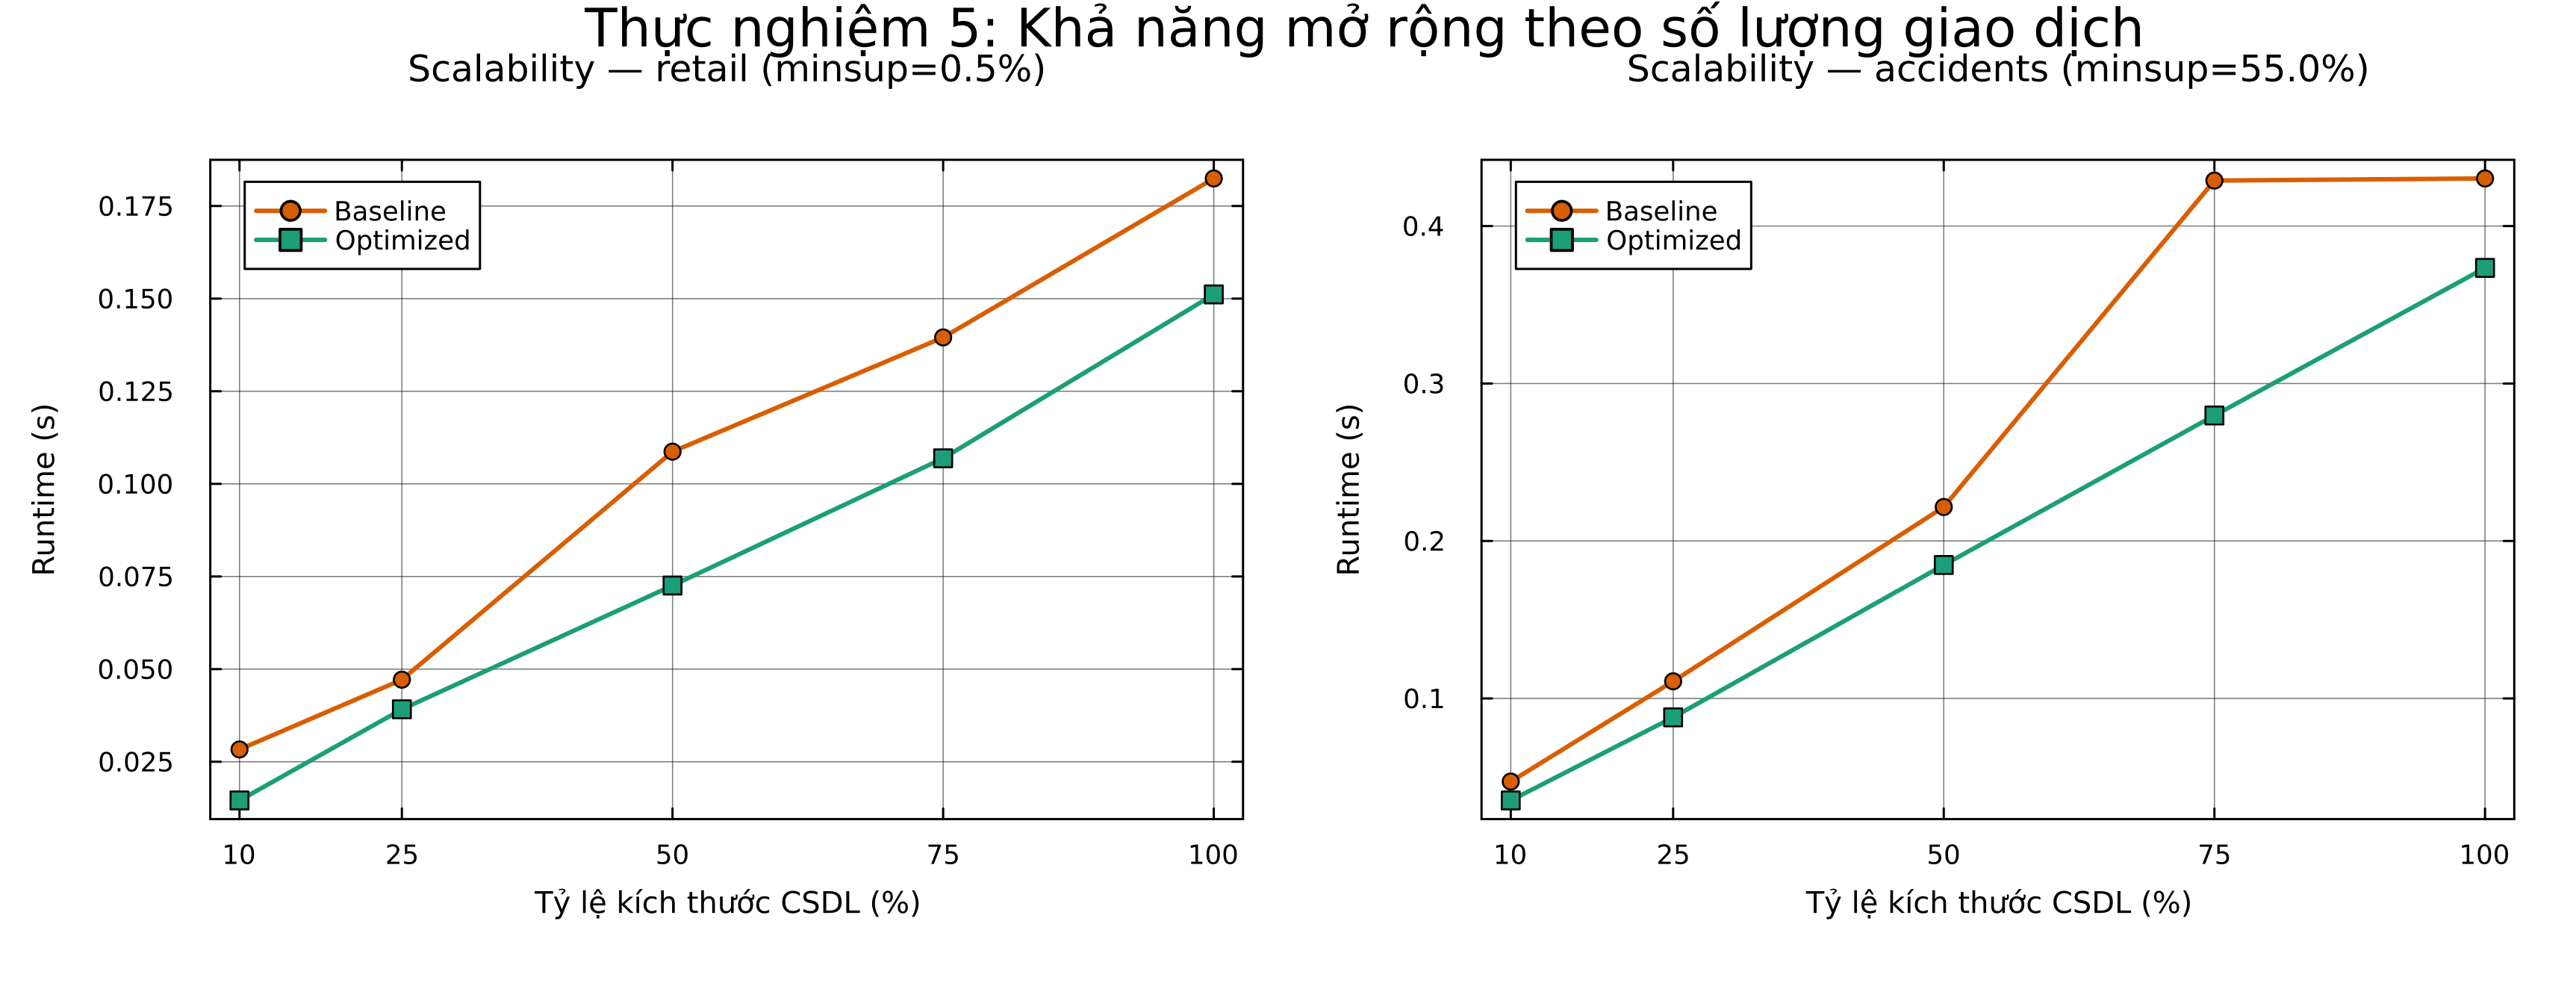

=== BẢNG KẾT QUẢ THỰC NGHIỆM 5: SCALABILITY ===


In [15]:
df_scale = CSV.read(joinpath(LOGS_DIR, "exp5_scalability.csv"), DataFrame)
println("=== BẢNG KẾT QUẢ THỰC NGHIỆM 5: SCALABILITY ===")
display(df_scale)

scale_plots = Plots.Plot[]
for ds in unique(df_scale.dataset)
    sub = filter(r -> r.dataset == ds, df_scale)
    pct = sub.fraction .* 100.0
    ms_pct = round(sub.minsup[1] * 100.0; digits=1)
    p = plot(
        pct,
        sub.time_base_s;
        label="Baseline",
        marker=:circle,
        linewidth=2,
        color=RGB(0.85, 0.37, 0.01),
        xticks=[10, 25, 50, 75, 100],
        xlabel="Tỷ lệ kích thước CSDL (%)",
        ylabel="Runtime (s)",
        title="Scalability — $ds (minsup=$ms_pct%)",
        legend=:topleft,
    )
    plot!(
        p,
        pct,
        sub.time_opt_s;
        label="Optimized",
        marker=:rect,
        linewidth=2,
        color=RGB(0.11, 0.62, 0.47),
    )
    push!(scale_plots, p)
end

fig4 = plot(
    scale_plots...;
    layout=(1, 2),
    size=(1150, 440),
    plot_title="Thực nghiệm 5: Khả năng mở rộng theo số lượng giao dịch",
    margin=5Plots.mm,
)
savefig(fig4, joinpath(FIG_DIR, "fig4_scalability.png"))
display(fig4)

### Nhận xét Thực nghiệm 5
- Thời gian chạy của `negFIN` tăng trưởng **gần như tuyến tính ($O(|DB|)$)** theo số lượng giao dịch trên cả hai tập:
  - **`Retail` (10% $\rightarrow$ 100%):** `Optimized` tăng từ `0.0145s` $\rightarrow$ `0.1511s` (~10.4x khi dữ liệu tăng 10x).
  - **`Accidents` (10% $\rightarrow$ 100%):** `Optimized` tăng từ `0.0352s` $\rightarrow$ `0.3734s` (~10.6x khi dữ liệu tăng 10x).
- **Lý giải:** Khi giữ cố định tỷ lệ `minsup`, phân bố tần suất item tương đối ổn định (số lượng tập phổ biến giữ gần như không đổi: ~544–692 trên `Retail` và ~3,628–4,160 trên `Accidents`), nên chi phí chủ yếu tăng tuyến tính theo pha quét CSDL và xây dựng BMC-tree (`O(nt * avg_len)`).

---
## Phần 8 — Thực Nghiệm 6: Ảnh Hưởng Của Độ Dài Giao Dịch Trung Bình

### Mục tiêu & Thiết lập
- Sinh 6 CSDL tổng hợp (`MersenneTwister(42 + i)`) cố định **10,000 giao dịch**, **80 items**, `minsup = 20%`, thay đổi **độ dài giao dịch trung bình** `avg_len` $\in \{10, 14, 18, 22, 26, 30\}$.
- Đồng thời đo thêm **số nút trên cây BMC-tree (`bmc_nodes`)** và **số frequent itemsets** để kiểm chứng trực tiếp dự đoán lý thuyết của bài báo gốc.

Row,avg_len,n_tx,n_items,minsup,nf,bmc_nodes,n_itemsets,time_base_s,time_opt_s,alloc_base_mb,alloc_opt_mb
,Int64,Int64,Int64,Float64,Int64,Int64,Int64,Float64,Float64,Float64,Float64
1,10,10000,80,0.2,6,63,6,0.003336,0.003055,0.032,0.017
2,14,10000,80,0.2,16,7393,19,0.006379,0.005119,4.527,0.819
3,18,10000,80,0.2,37,56883,54,0.023268,0.009175,44.694,9.359
4,22,10000,80,0.2,69,140668,134,0.093516,0.016358,166.147,56.562
5,26,10000,80,0.2,80,192864,308,0.13213,0.029195,271.431,122.03
6,30,10000,80,0.2,80,222694,833,0.212843,0.043614,354.227,219.006


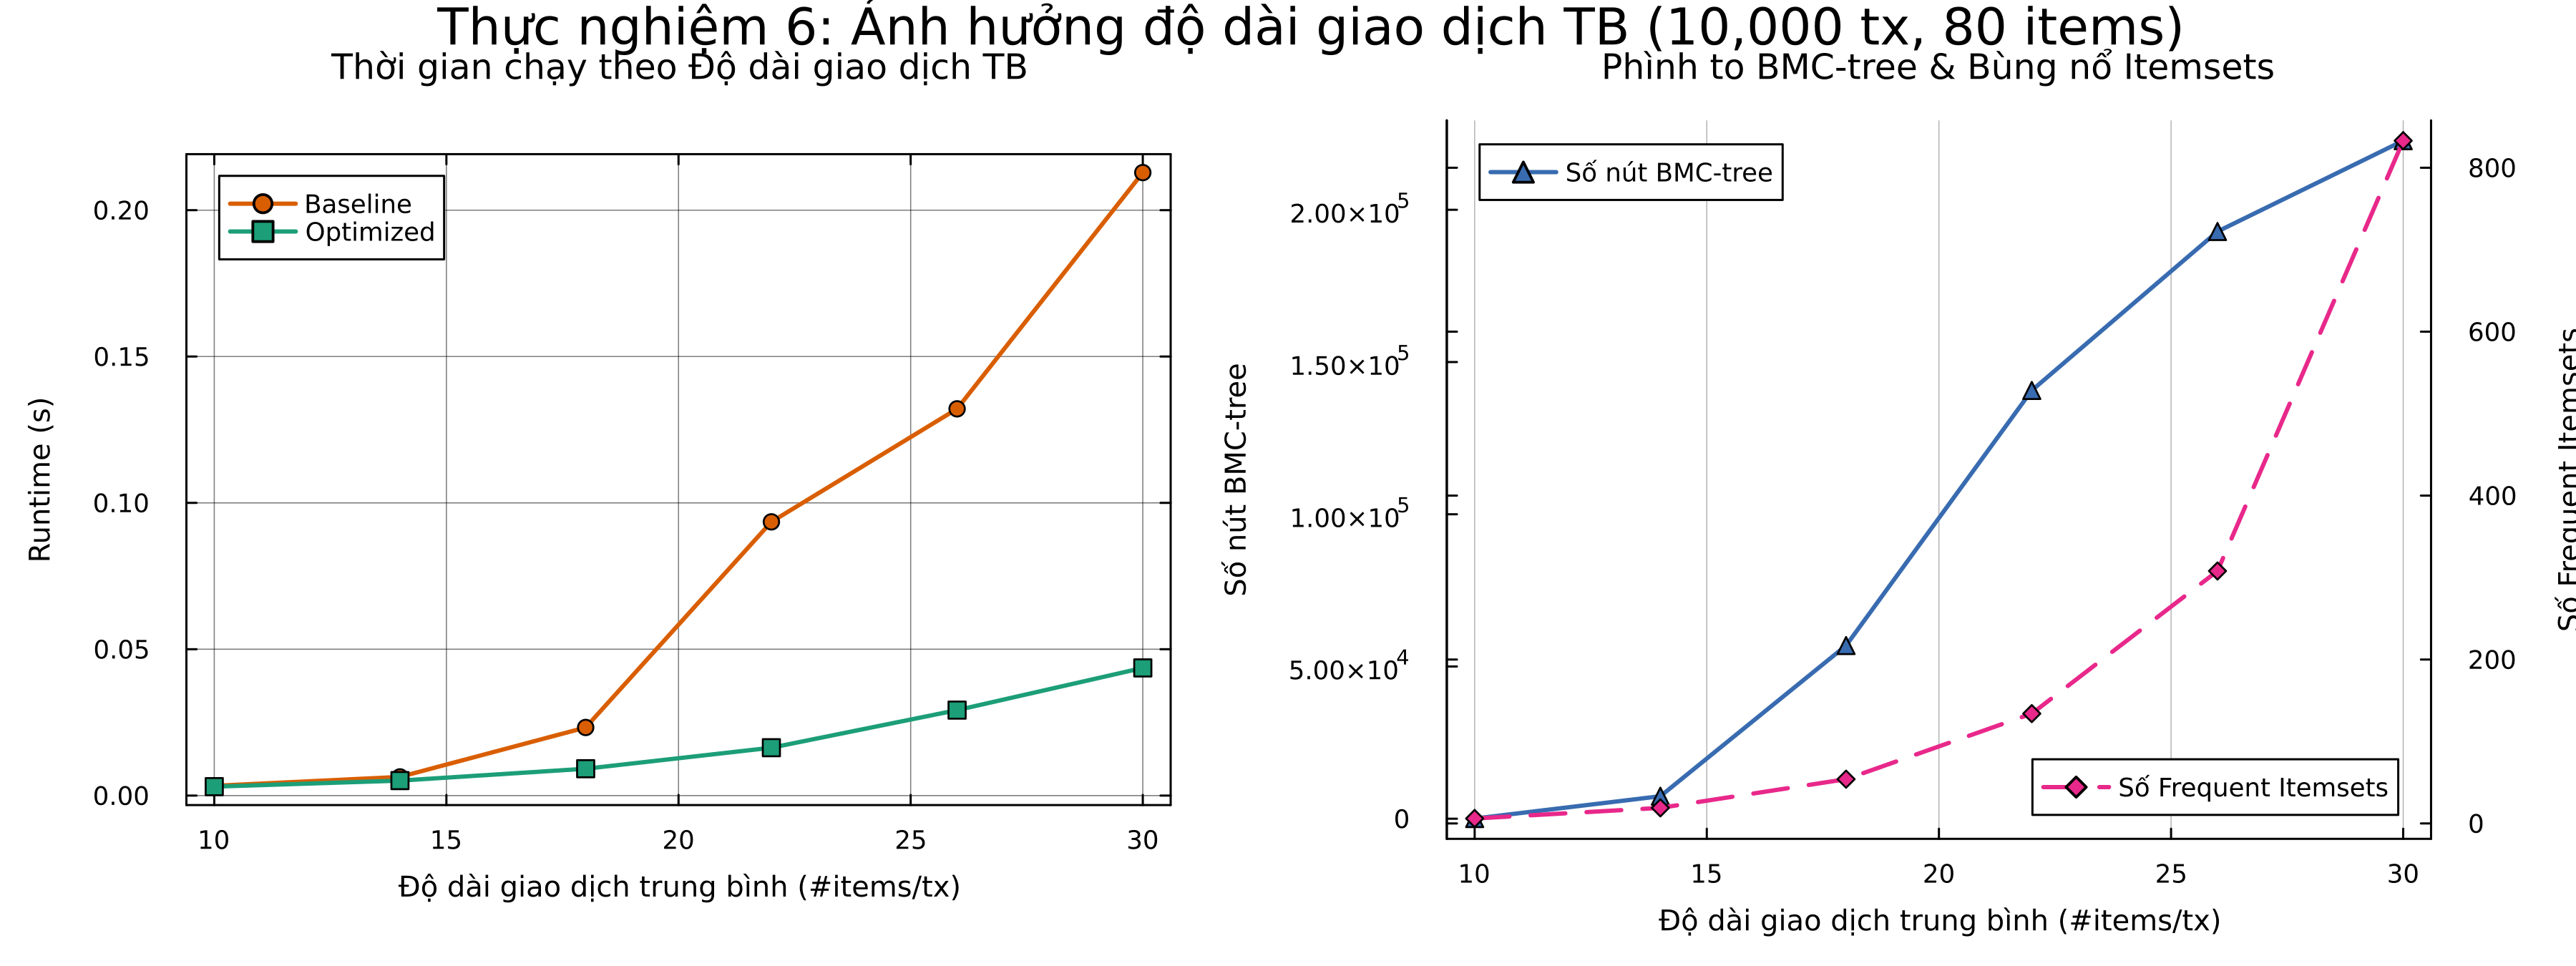

=== BẢNG KẾT QUẢ THỰC NGHIỆM 6: ĐỘ DÀI GIAO DỊCH TRUNG BÌNH ===


In [16]:
df_len = CSV.read(joinpath(LOGS_DIR, "exp6_tx_length.csv"), DataFrame)
println("=== BẢNG KẾT QUẢ THỰC NGHIỆM 6: ĐỘ DÀI GIAO DỊCH TRUNG BÌNH ===")
display(df_len)

p_rt_len = plot(
    df_len.avg_len,
    df_len.time_base_s;
    label="Baseline",
    marker=:circle,
    linewidth=2,
    color=RGB(0.85, 0.37, 0.01),
    xlabel="Độ dài giao dịch trung bình (#items/tx)",
    ylabel="Runtime (s)",
    title="Thời gian chạy theo Độ dài giao dịch TB",
    legend=:topleft,
)
plot!(
    p_rt_len,
    df_len.avg_len,
    df_len.time_opt_s;
    label="Optimized",
    marker=:rect,
    linewidth=2,
    color=RGB(0.11, 0.62, 0.47),
)

p_tree = plot(
    df_len.avg_len,
    df_len.bmc_nodes;
    label="Số nút BMC-tree",
    marker=:utriangle,
    linewidth=2,
    color=RGB(0.22, 0.42, 0.69),
    xlabel="Độ dài giao dịch trung bình (#items/tx)",
    ylabel="Số nút BMC-tree",
    title="Phình to BMC-tree & Bùng nổ Itemsets",
    legend=:topleft,
)
p_tree_r = twinx(p_tree)
plot!(
    p_tree_r,
    df_len.avg_len,
    df_len.n_itemsets;
    label="Số Frequent Itemsets",
    marker=:diamond,
    linestyle=:dash,
    linewidth=2,
    color=RGB(0.91, 0.16, 0.54),
    ylabel="Số Frequent Itemsets",
    legend=:bottomright,
)

fig5 = plot(
    p_rt_len,
    p_tree;
    layout=(1, 2),
    size=(1200, 450),
    plot_title="Thực nghiệm 6: Ảnh hưởng độ dài giao dịch TB (10,000 tx, 80 items)",
    margin=5Plots.mm,
)
savefig(fig5, joinpath(FIG_DIR, "fig5_tx_length.png"))
display(fig5)

### Nhận xét Thực nghiệm 6
- Khi `avg_len` tăng từ `10` lên `30`, số lượng nút trên BMC-tree tăng vọt hơn **3,500 lần** (từ `63` lên `222,694` nút) và số frequent itemsets tăng từ `6` lên `833`.
- **Lý giải theo lý thuyết `negFIN`:** Giao dịch càng dài thì khả năng chia sẻ tiền tố chung trên BMC-tree càng giảm, làm phình to số nút BMC-tree và kéo theo kích thước `Nodeset`/`NegNodeset` ($n$) tăng mạnh $\rightarrow$ chi phí $O(l \cdot n)$ tăng phi tuyến.
- Chính trong kịch bản giao dịch dài (`avg_len = 30`), lợi thế của bản **Optimized** thể hiện rõ nhất: chỉ mất **`0.0436s`** so với **`0.2128s`** của **Baseline** (**tăng tốc 4.88x**) nhờ nén toàn bộ `nf = 80` bit vào một giá trị `UInt128` nằm gọn trên thanh ghi CPU.

---
## Phần 9: Tổng Kết, So Sánh Với SPMF (Java) & Đề Xuất Hướng Tối Ưu Tiếp Theo

### 1. Điểm mạnh & điểm yếu của `negFIN` (Julia) so với SPMF (Java)
- **Điểm mạnh của cài đặt Julia:**
  - Biên dịch trực tiếp sang mã máy LLVM không có overhead object boxing như JVM; các kiểu `UInt64`, `UInt128`, `NTuple{N, UInt64}` được cấp phát phẳng trong mảng liên tiếp (SoA), tối ưu CPU cache.
  - Không cần khởi động JVM nặng khi nhúng vào pipeline khoa học dữ liệu; hỗ trợ streaming (`emit_fn`) giúp kiểm soát bộ nhớ tốt.
- **Điểm yếu / Hạn chế cố hữu của `negFIN`:**
  - Khi `nf = |F1|` rất lớn trên dữ liệu thưa ở `minsup` cực thấp (như `Retail` hoặc `Kosarak`), mỗi nút BMC-tree phải mang một `bitmap_code` dài `ceil(nf / 64)` từ `UInt64`, làm tiêu tốn RAM nhiều hơn so với cấu trúc chỉ lưu `pre-order` như POC-tree của FIN/dFIN (đúng như nhận định tại Mục 5.3.2 bài báo gốc).
  - Lần chạy đầu tiên trong phiên Julia tốn thời gian biên dịch JIT (nhưng hoàn toàn bị khấu hao khi chạy nhiều ngưỡng hoặc batch lớn).

### 2. Đề xuất 3 hướng tối ưu hóa tiếp theo
1. **Song song hóa đa luồng (`Threads.@threads`) ở tầng 1 của Set-Enumeration Tree:**
   - Mỗi cây con bắt đầu từ nút `pos` $\in 1..n_f$ ở tầng 1 chỉ **đọc** mảng `nodesets` và hoàn toàn độc lập về bộ đệm ghi cục bộ (`prefix`, `equiv_stack`). Sử dụng lập lịch động (`Threads.@spawn`) giúp cân bằng tải tốt giữa các nhánh nặng (item có support thấp ở đầu `L1`) và nhánh nhẹ (cuối `L1`).
2. **Nén Bitmap theo đoạn (Trimmed / Sparse Bitset) cho dữ liệu thưa có $n_f$ lớn:**
   - Theo **Property 1** (bài báo gốc), toàn bộ *don't-care section* (các bit thấp hơn `index(i)`) luôn bằng `0`; hơn nữa trên dữ liệu thưa, phần lớn các word `UInt64` đầu cũng bằng `0`. Lưu bitmap dưới dạng `(first_word::UInt16, words::Vector{UInt64})` hoặc danh sách `(word_idx, word_val)` chỉ giữ các word khác 0 sẽ giảm mạnh Peak RAM trên `Retail`/`T10I4D100K`.
3. **Mở rộng khai thác Tập Đóng (Closed FIM) & Tập Cực Đại (Maximal FIM) trên `NegNodeset`:**
   - Theo định hướng Mục 7 của Aryabarzan et al. (2018), tích hợp kiểm tra tính đóng trực tiếp trên `NegNodeset` và `equivalent_items` cho phép bỏ qua hàng triệu tập con dư thừa trên dữ liệu dày đặc (`Chess`, `Pumsb`, `Accidents`) ở ngưỡng `minsup` rất thấp.